In [6]:
# 1. CONFIGURACIÓN GRÁFICA Y CARGA DE DATOS PROCESADOS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configuración estética de los gráficos
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10

# Carga del dataset procesado (nuevo)
df = pd.read_csv('../data/clean/bank_clean.csv')

print(f"Dataset cargado con éxito: {df.shape[0]} filas y {df.shape[1]} columnas.")

Dataset cargado con éxito: 43000 filas y 34 columnas.


In [3]:
# 2. ESTADÍSTICA DESCRIPTIVA GENERAL

# Variables numéricas: media, mediana (50%), desviación típica y rangos intercuartílicos
print("--- ESTADÍSTICA DESCRIPTIVA (VARIABLES NUMÉRICAS) ---")
display(df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']])

# Variables categóricas: valores únicos, moda y frecuencia del valor dominante
print("\n--- RESUMEN DE VARIABLES CATEGÓRICAS ---")
display(df.describe(include=['object', 'category']).T[['count', 'unique', 'top', 'freq']])

--- ESTADÍSTICA DESCRIPTIVA (VARIABLES NUMÉRICAS) ---


,count,mean,std,min,25%,50%,75%,max
age,43000.0,39.806326,9.961792,17.000,33.00000,38.0000,46.00000,98.000
default,43000.0,0.000070,0.008352,0.000,0.00000,0.0000,0.00000,1.000
housing,43000.0,0.547070,0.497785,0.000,0.00000,1.0000,1.00000,1.000
loan,43000.0,0.151907,0.358935,0.000,0.00000,0.0000,0.00000,1.000
duration,43000.0,257.739279,258.666033,0.000,102.00000,179.0000,319.00000,4918.000
campaign,43000.0,2.567233,2.772294,1.000,1.00000,2.0000,3.00000,56.000
pdays,43000.0,962.330953,187.260394,0.000,999.00000,999.0000,999.00000,999.000
previous,43000.0,0.174023,0.497366,0.000,0.00000,0.0000,0.00000,7.000
emp.var.rate,43000.0,0.077128,1.573898,-3.400,-1.80000,1.1000,1.40000,1.400
cons.price.idx,43000.0,93.575245,0.576888,92.201,93.07500,93.7490,93.99400,94.767



--- RESUMEN DE VARIABLES CATEGÓRICAS ---


C:\Users\Carlos Antonio\AppData\Local\Temp\ipykernel_6676\2846957509.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include=['object', 'category']).T[['count', 'unique', 'top', 'freq']])


,count,unique,top,freq
job,43000,11,admin.,11218
marital,43000,3,married,26084
education,43000,7,university.degree,14529
contact,43000,2,cellular,27396
poutcome,43000,3,nonexistent,37103
y,43000,2,no,38156
date,42752,1825,2018-02-28,95
id_,43000,43000,089b39d8-e4d0-461b-87d4-814d71e0e079,1
Dt_Customer,43000,1096,2012-08-10,79
age_group,43000,4,30-45 adulto_joven,25010


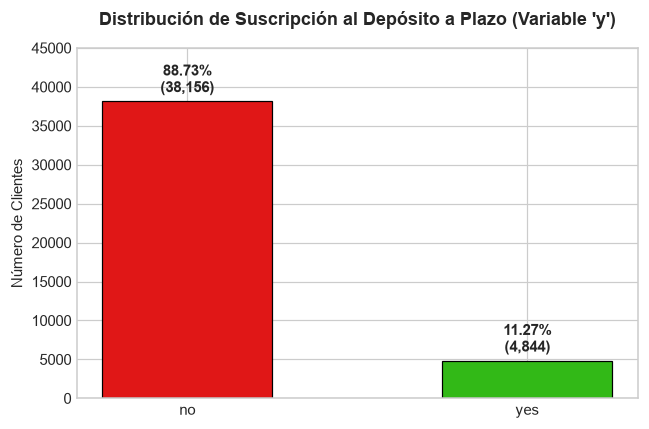

In [8]:
# 3. ANÁLISIS DE LA VARIABLE OBJETIVO

conteo_y = df['y'].value_counts()
porcentaje_y = df['y'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6, 4))
colores = ["#E01717", "#32B917"]

bars = ax.bar(conteo_y.index, conteo_y.values, color=colores, width=0.5, edgecolor='black', linewidth=0.8)

# Añadir etiquetas de porcentaje sobre cada barra
for bar, pct in zip(bars, porcentaje_y):
    altura = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, altura + 600, f'{pct:.2f}%\n({int(altura):,})', 
            ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_title("Distribución de Suscripción al Depósito a Plazo (Variable 'y')", fontweight='bold', pad=15)
ax.set_ylabel("Número de Clientes")
ax.set_ylim(0, 45000)
plt.tight_layout()
plt.show()

--- RESULTADO DEL CONTRASTE ESTADÍSTICO ---
Coeficiente Biserial-Puntual (r_pb): -0.2657
p-valor: 0.00e+00
Conclusión: p < 0.05 -> Relación inversa estadísticamente significativa.
A menores tipos de interés (euribor), mayor contratación de depósitos.


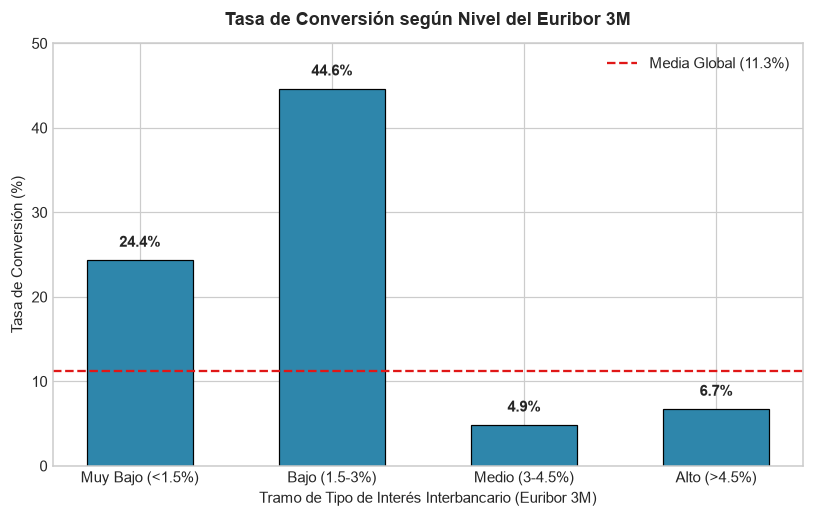

In [11]:
# IMPACTO DEL EURIBOR 3M EN LA CONTRATACIÓN (CORRELACIÓN BISERIAL)

# PARTE ESTADÍSTICA: Correlación Biserial-Puntual
# - Hipótesis nula (H0): No existe asociación lineal entre euribor3m y la contratación.
# - Justificación: Se utiliza 'pointbiserialr' porque cruzamos una variable cuantitativa
#   continua (euribor3m) con una dicotómica natural (target_numeric: 0 ó 1).
r_pb, p_val_pb = stats.pointbiserialr(df['target_numeric'], df['euribor3m'])

print("--- RESULTADO DEL CONTRASTE ESTADÍSTICO ---")
print(f"Coeficiente Biserial-Puntual (r_pb): {r_pb:.4f}")
print(f"p-valor: {p_val_pb:.2e}")
if p_val_pb < 0.05:
    print("Conclusión: p < 0.05 -> Relación inversa estadísticamente significativa.")
    print("A menores tipos de interés (euribor), mayor contratación de depósitos.")

# CÁLCULO DE MÉTRICAS AGRUPADAS (PANDAS)
# Discretizamos el Euribor en 4 bandas operativas del mercado monetario
df['euribor_tramo'] = pd.cut(
    df['euribor3m'],
    bins=[0, 1.5, 3.0, 4.5, 5.5],
    labels=['Muy Bajo (<1.5%)', 'Bajo (1.5-3%)', 'Medio (3-4.5%)', 'Alto (>4.5%)']
)

# Agrupamos calculando volumen de clientes y tasa de conversión porcentual
euribor_stats = df.groupby('euribor_tramo', observed=False)['target_numeric'].agg(['count', 'mean']).reset_index()
euribor_stats['pct'] = euribor_stats['mean'] * 100

fig, ax = plt.subplots(figsize=(7.5, 4.8))
# Gráfico de barras con ancho calibrado y borde para definir contraste
bars = ax.bar(
    euribor_stats['euribor_tramo'],
    euribor_stats['pct'],
    color='#2E86AB',
    edgecolor='black',
    linewidth=0.8,
    width=0.55
)
# Etiquetas dinámicas de porcentaje encima de cada barra
for bar in bars:
    altura = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        altura + 1.2,
        f"{altura:.1f}%",
        ha='center',
        va='bottom',
        fontweight='bold',
        fontsize=9.5
    )
# Línea de referencia global del banco
media_global_pct = df['target_numeric'].mean() * 100
ax.axhline(media_global_pct, color='#E01717', linestyle='--', linewidth=1.5, label=f'Media Global ({media_global_pct:.1f}%)')

# Títulos, límites y etiquetas de negocio
ax.set_title("Tasa de Conversión según Nivel del Euribor 3M", fontweight='bold', pad=12)
ax.set_ylabel("Tasa de Conversión (%)")
ax.set_xlabel("Tramo de Tipo de Interés Interbancario (Euribor 3M)")
ax.set_ylim(0, 50)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

--- RESULTADO DEL CONTRASTE ESTADÍSTICO (PUNTO 2) ---
Estadístico Chi-cuadrado (χ²): 880.25
Grados de libertad: 3
p-valor: 1.70e-190
Conclusión: p < 0.05 -> Se rechaza la independencia.
El tramo de edad determina de manera decisiva la tasa de conversión.


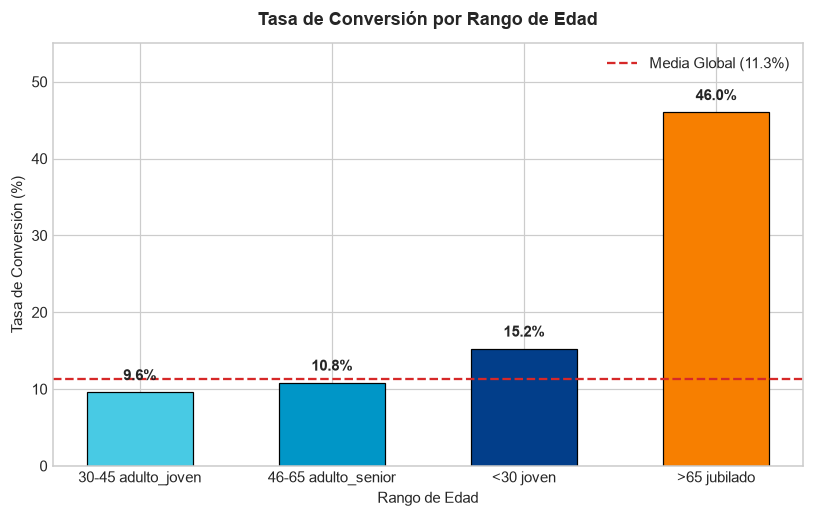

In [13]:
# SEGMENTACIÓN DEMOGRÁFICA POR EDAD 

# PARTE ESTADÍSTICA: Test Chi-cuadrado de Independencia (χ²)
# - Hipótesis nula (H0): La decisión de suscripción es independiente del grupo de edad.
# - Justificación: Comparamos dos variables categóricas (age_group vs y). El test χ²
#   compara las frecuencias empíricas frente a las esperadas por mero azar.
tabla_contingencia_edad = pd.crosstab(df['age_group'], df['y'])
chi2_edad, p_val_edad, dof_edad, _ = stats.chi2_contingency(tabla_contingencia_edad)

print("--- RESULTADO DEL CONTRASTE ESTADÍSTICO (PUNTO 2) ---")
print(f"Estadístico Chi-cuadrado (χ²): {chi2_edad:.2f}")
print(f"Grados de libertad: {dof_edad}")
print(f"p-valor: {p_val_edad:.2e}")
if p_val_edad < 0.05:
    print("Conclusión: p < 0.05 -> Se rechaza la independencia.")
    print("El tramo de edad determina de manera decisiva la tasa de conversión.")

# CÁLCULO DE MÉTRICAS AGRUPADAS (PANDAS)
age_stats = df.groupby('age_group', observed=False)['target_numeric'].agg(['count', 'mean']).reset_index()
age_stats['pct'] = age_stats['mean'] * 100

fig, ax = plt.subplots(figsize=(7.5, 4.8))
# Paleta cromática semántica: azules para tramos laborales y naranja para Jubilados
colores_edad = ['#48CAE4', '#0096C7', '#023E8A', '#F77F00']
bars = ax.bar(
    age_stats['age_group'],
    age_stats['pct'],
    color=colores_edad,
    edgecolor='black',
    linewidth=0.8,
    width=0.55
)
# Etiquetas numéricas sobre las barras
for bar in bars:
    altura = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        altura + 1.2,
        f"{altura:.1f}%",
        ha='center',
        va='bottom',
        fontweight='bold',
        fontsize=9.5
    )
# Benchmark promedio
ax.axhline(media_global_pct, color='#D62828', linestyle='--', linewidth=1.5, label=f'Media Global ({media_global_pct:.1f}%)')
ax.set_title("Tasa de Conversión por Rango de Edad", fontweight='bold', pad=12)
ax.set_ylabel("Tasa de Conversión (%)")
ax.set_xlabel("Rango de Edad")
ax.set_ylim(0, 55)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

--- RESULTADO DEL CONTRASTE ESTADÍSTICO (PUNTO 6) ---
Media ingresos 'No': 93,324.60 € | Media ingresos 'Sí': 92,584.30 €
Estadístico t: -0.9611
p-valor: 0.3365
Conclusión: p >= 0.05 -> NO se puede rechazar la hipótesis nula (H0).
No existen diferencias estadísticamente significativas en el nivel de ingresos.


C:\Users\Carlos Antonio\AppData\Local\Temp\ipykernel_6676\1469802021.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Carlos Antonio\AppData\Local\Temp\ipykernel_6676\1469802021.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


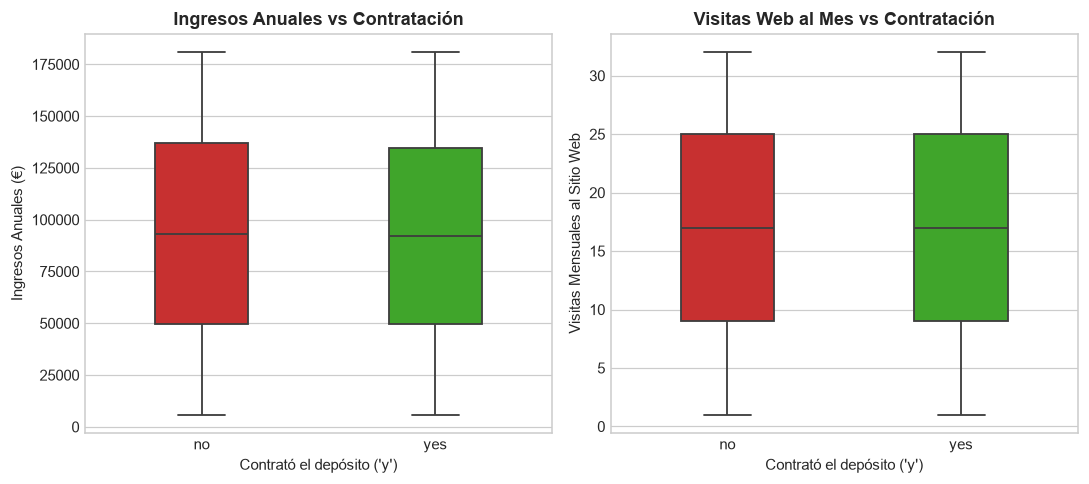

In [19]:
# CONTRASTE DE HIPÓTESIS SOBRE VARIABLES DEL CLIENTE 

# PARTE ESTADÍSTICA: Test t de Student para Muestras Independientes
# - Hipótesis nula (H0): La media de ingresos anuales de quienes contratan (yes)
#   es IGUAL a la media de ingresos de quienes rechazan (no).
# - Justificación: Comparamos las medias de una variable continua normalizada (Income)
#   entre dos poblaciones independientes.
inc_no = df[df['y'] == 'no']['Income']
inc_yes = df[df['y'] == 'yes']['Income']
t_stat, p_val_ttest = stats.ttest_ind(inc_yes, inc_no)

print("--- RESULTADO DEL CONTRASTE ESTADÍSTICO (PUNTO 6) ---")
print(f"Media ingresos 'No': {inc_no.mean():,.2f} € | Media ingresos 'Sí': {inc_yes.mean():,.2f} €")
print(f"Estadístico t: {t_stat:.4f}")
print(f"p-valor: {p_val_ttest:.4f}")
if p_val_ttest >= 0.05:
    print("Conclusión: p >= 0.05 -> NO se puede rechazar la hipótesis nula (H0).")
    print("No existen diferencias estadísticamente significativas en el nivel de ingresos.")

# ESTRUCTURA Y COMPOSICIÓN GRÁFICA (SUBPLOTS EN PANEL 1x2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))
# Subgráfico 1: Diagrama de caja de Ingresos Anuales
sns.boxplot(
    data=df,
    x='y',
    y='Income',
    palette={'no': '#E01717', 'yes': '#32B917'},
    width=0.4,
    linewidth=1.2,
    ax=ax1
)
ax1.set_title("Ingresos Anuales vs Contratación", fontweight='bold')
ax1.set_ylabel("Ingresos Anuales (€)")
ax1.set_xlabel("Contrató el depósito ('y')")

# Subgráfico 2: Diagrama de caja de Navegación Web Mensual
sns.boxplot(
    data=df,
    x='y',
    y='NumWebVisitsMonth',
    palette={'no': '#E01717', 'yes': '#32B917'},
    width=0.4,
    linewidth=1.2,
    ax=ax2
)
ax2.set_title("Visitas Web al Mes vs Contratación", fontweight='bold')
ax2.set_ylabel("Visitas Mensuales al Sitio Web")
ax2.set_xlabel("Contrató el depósito ('y')")

plt.tight_layout()
plt.show()

--- RESULTADO DEL CONTRASTE ESTADÍSTICO (PUNTO 5) ---
Estadístico Chi-cuadrado (χ²): 4459.57
Grados de libertad: 2
p-valor: 0.00e+00
Conclusión: p < 0.05 -> Dependencia categórica extrema.
El éxito previo es el predictor individual con mayor fuerza estadística del dataset.


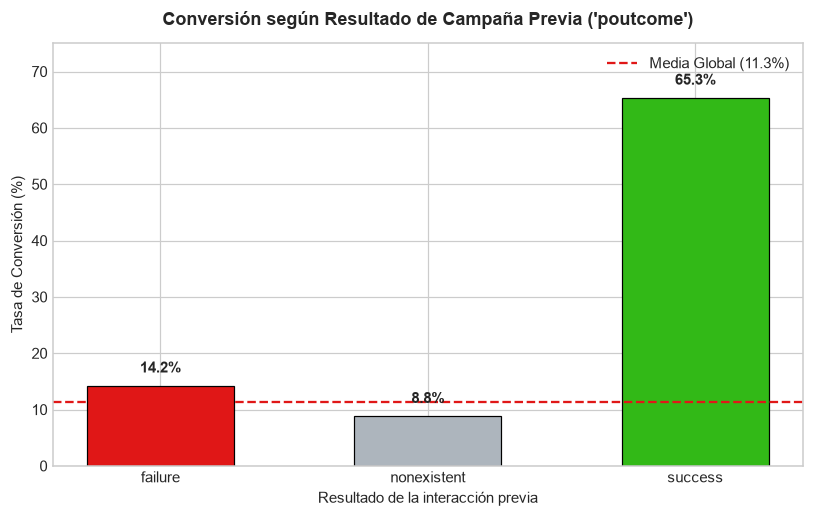

In [18]:
# FIDELIZACIÓN Y RESULTADO PREVIO

# PARTE ESTADÍSTICA: Test Chi-cuadrado de Independencia (χ²)
# - Hipótesis nula (H0): La respuesta actual es independiente del resultado de la campaña previa.
# - Justificación: Cruce de dos variables categóricas nominales (poutcome vs y).
tabla_contingencia_pout = pd.crosstab(df['poutcome'], df['y'])
chi2_pout, p_val_pout, dof_pout, _ = stats.chi2_contingency(tabla_contingencia_pout)

print("--- RESULTADO DEL CONTRASTE ESTADÍSTICO (PUNTO 5) ---")
print(f"Estadístico Chi-cuadrado (χ²): {chi2_pout:.2f}")
print(f"Grados de libertad: {dof_pout}")
print(f"p-valor: {p_val_pout:.2e}")
if p_val_pout < 0.05:
    print("Conclusión: p < 0.05 -> Dependencia categórica extrema.")
    print("El éxito previo es el predictor individual con mayor fuerza estadística del dataset.")

# CÁLCULO DE MÉTRICAS AGRUPADAS (PANDAS)
pout_stats = df.groupby('poutcome', observed=False)['target_numeric'].agg(['count', 'mean']).reset_index()
pout_stats['pct'] = pout_stats['mean'] * 100

# 3. ESTRUCTURA Y COMPOSICIÓN GRÁFICA
fig, ax = plt.subplots(figsize=(7.5, 4.8))

# Rojo para fallo anterior, gris para cliente nuevo (inexistente), verde para éxito previo
colores_pout = ['#E01717', '#ADB5BD', '#32B917']
bars = ax.bar(
    pout_stats['poutcome'],
    pout_stats['pct'],
    color=colores_pout,
    edgecolor='black',
    linewidth=0.8,
    width=0.55
)
# Etiquetas con porcentaje sobre cada columna
for bar in bars:
    altura = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        altura + 1.8,
        f"{altura:.1f}%",
        ha='center',
        va='bottom',
        fontweight='bold',
        fontsize=9.5
    )

ax.axhline(media_global_pct, color='#E01717', linestyle='--', linewidth=1.5, label=f"Media Global ({media_global_pct:.1f}%)")

ax.set_title("Conversión según Resultado de Campaña Previa ('poutcome')", fontweight='bold', pad=12)
ax.set_xlabel("Resultado de la interacción previa")
ax.set_ylabel("Tasa de Conversión (%)")
ax.set_ylim(0, 75)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

--- RESULTADO DEL CONTRASTE ESTADÍSTICO (PUNTO 3) ---
Estadístico U de Mann-Whitney: 151332684.00
p-valor: 0.00e+00
Mediana llamadas NO: 163 segundos (2.7 min)
Mediana llamadas SÍ: 449 segundos (7.5 min)
Conclusión: p < 0.05 -> La duración de llamadas exitosas es significativamente mayor.


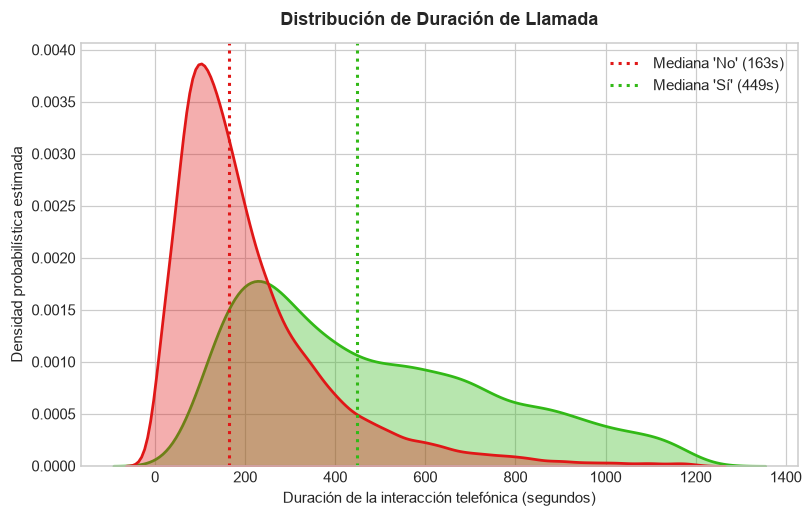

In [14]:
# ANÁLISIS DE DURACIÓN DE LLAMADA

# PARTE ESTADÍSTICA: Test U de Mann-Whitney (Distribución Asimétrica)
# - Hipótesis nula (H0): Las llamadas con éxito ('yes') y sin éxito ('no') tienen
#   la misma distribución de rangos de duración.
# - Justificación: La duración presenta una marcada asimetría positiva a la derecha
#   (no normalidad), por lo que el test no paramétrico de Mann-Whitney sobre medianas
#   es el estándar riguroso en lugar del t-Student.
dur_no = df[df['y'] == 'no']['duration']
dur_yes = df[df['y'] == 'yes']['duration']
u_stat, p_val_mann = stats.mannwhitneyu(dur_yes, dur_no)

mediana_no = dur_no.median()
mediana_yes = dur_yes.median()

print("--- RESULTADO DEL CONTRASTE ESTADÍSTICO (PUNTO 3) ---")
print(f"Estadístico U de Mann-Whitney: {u_stat:.2f}")
print(f"p-valor: {p_val_mann:.2e}")
print(f"Mediana llamadas NO: {mediana_no:.0f} segundos ({mediana_no/60:.1f} min)")
print(f"Mediana llamadas SÍ: {mediana_yes:.0f} segundos ({mediana_yes/60:.1f} min)")
if p_val_mann < 0.05:
    print("Conclusión: p < 0.05 -> La duración de llamadas exitosas es significativamente mayor.")

# ESTRUCTURA Y COMPOSICIÓN GRÁFICA (KDE PLOT CON LÍNEAS DE MEDIANA)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
# Estimación de densidad por kernel (KDE) acotada a 1.200 segundos (20 min) para eliminar cola extrema
sns.kdeplot(
    data=df[df['duration'] <= 1200],
    x='duration',
    hue='y',
    common_norm=False,
    fill=True,
    palette={'no': '#E01717', 'yes': '#32B917'},
    alpha=0.35,
    linewidth=1.8,
    ax=ax
)
# Marcar formalmente las medianas calculadas en el gráfico
ax.axvline(mediana_no, color='#E01717', linestyle=':', linewidth=2, label=f"Mediana 'No' ({mediana_no:.0f}s)")
ax.axvline(mediana_yes, color='#32B917', linestyle=':', linewidth=2, label=f"Mediana 'Sí' ({mediana_yes:.0f}s)")

ax.set_title("Distribución de Duración de Llamada", fontweight='bold', pad=12)
ax.set_xlabel("Duración de la interacción telefónica (segundos)")
ax.set_ylabel("Densidad probabilística estimada")
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

--- RESULTADO DEL CONTRASTE ESTADÍSTICO (PUNTO 4) ---
Coeficiente de Spearman (rho): -0.0634
p-valor: 1.69e-39
Conclusión: p < 0.05 -> Existe correlación monótona negativa estadísticamente sólida.
A mayor insistencia de contactos en la misma campaña, menor tasa de éxito.


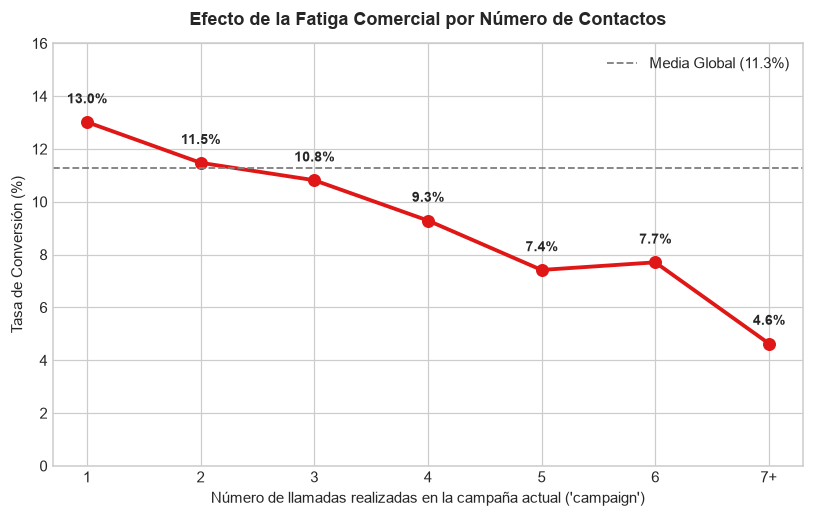

In [15]:
# FATIGA COMERCIAL POR CONTACTOS REITERADOS (CORRELACIÓN DE SPEARMAN)

# PARTE ESTADÍSTICA: Correlación Monótona de Rangos de Spearman
# - Hipótesis nula (H0): No existe correlación monótona entre el número de llamadas
#   y la probabilidad de conversión.
# - Justificación: La relación de fatiga no es lineal decreciente constante, sino
#   ordinal y decreciente. Spearman evalúa la consistencia de la caída sin asumir linealidad.
rho_spearman, p_val_spearman = stats.spearmanr(df['campaign'], df['target_numeric'])

print("--- RESULTADO DEL CONTRASTE ESTADÍSTICO (PUNTO 4) ---")
print(f"Coeficiente de Spearman (rho): {rho_spearman:.4f}")
print(f"p-valor: {p_val_spearman:.2e}")
if p_val_spearman < 0.05:
    print("Conclusión: p < 0.05 -> Existe correlación monótona negativa estadísticamente sólida.")
    print("A mayor insistencia de contactos en la misma campaña, menor tasa de éxito.")

# CÁLCULO DE MÉTRICAS Y COLAPSO DE COLA LARGA (PANDAS)
# Agrupamos llamadas >= 7 en '7+' para evitar distorsiones estadísticas en valores extremos
df['camp_group'] = df['campaign'].apply(lambda x: str(x) if x <= 6 else '7+')
orden_contactos = ['1', '2', '3', '4', '5', '6', '7+']

camp_stats = df.groupby('camp_group', observed=False)['target_numeric'].agg(['count', 'mean']).reindex(orden_contactos).reset_index()
camp_stats['pct'] = camp_stats['mean'] * 100

# ESTRUCTURA Y COMPOSICIÓN GRÁFICA
fig, ax = plt.subplots(figsize=(7.5, 4.8))
# Gráfico de línea con puntos gruesos para mostrar la curva de decaimiento
ax.plot(
    camp_stats['camp_group'],
    camp_stats['pct'],
    marker='o',
    linewidth=2.5,
    color='#E01717',
    markersize=7.5
)
# Anotación exacta del porcentaje en cada hito de contacto
for i, row in camp_stats.iterrows():
    ax.text(
        i,
        row['pct'] + 0.6,
        f"{row['pct']:.1f}%",
        ha='center',
        va='bottom',
        fontweight='bold',
        fontsize=9
    )
# Benchmark de referencia
ax.axhline(media_global_pct, color='gray', linestyle='--', linewidth=1.2, label=f"Media Global ({media_global_pct:.1f}%)")

ax.set_title("Efecto de la Fatiga Comercial por Número de Contactos", fontweight='bold', pad=12)
ax.set_xlabel("Número de llamadas realizadas en la campaña actual ('campaign')")
ax.set_ylabel("Tasa de Conversión (%)")
ax.set_ylim(0, 16)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()